# T41–T43 · Modelo físico, elevación y calibración

**Pregunta.** ¿Qué estructura aporta la física por viaje y cuánto se conserva al transferir una calibración de ajuste a la semana reservada?

Los periodos se fijan por salida. El Modelo A usa los Wh por distancia registrada y T40 aporta la referencia original. Los supuestos físicos están en `consumo/config.yaml`. Se reutiliza el cálculo de rodadura y aerodinámica de T16 mediante el mismo núcleo vectorizado de `modelo_b.py`. Los coeficientes describen un escenario representativo, a falta de medidas de Helbiz.

Con distancia registrada \(d\), velocidad media \(d/t\) y desnivel \(\Delta z\) se calcula el trabajo equivalente de rueda. Se suman \(C_{rr}mg\sqrt{d^2-\Delta z^2}\), \(\rho C_dA (d/t)^2d/2\) y \(mg\Delta z\). Se toma el máximo con cero y se divide por 3 600 y por el producto de eficiencias. La electrónica de a bordo (controlador, conexión y luces) añade una potencia constante durante el viaje, también en las bajadas. Los arranques y frenadas no se modelan por falta de perfil de velocidad: los recoge la calibración, que escala solo rodadura y aire porque son las pérdidas que crecen con la distancia, y deja el trabajo del desnivel en su valor físico. La densidad viene de temperatura y presión horarias de aire seco. El viento se lleva de 10 m a la altura del conductor con un perfil logarítmico y se muestra como escenario por su incertidumbre en calle. [Modelo de fuerzas](https://doi.org/10.3390/su15118976) · [Meteorología histórica](https://open-meteo.com/en/docs/historical-weather-api)

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ajustes import cargar_ajustes
from analisis_fisico import guardar, publicar_fisico
from comun.config import cargar_config
from comun.figuras import guardar_figura, plt

v, fisico, desnivel = publicar_fisico()
f = fisico.set_index("periodo")
a, r = f.loc["ajuste"], f.loc["reservada"]
ref = cargar_config()["patinete"]["consumo_wh_km"]
assert np.isclose(a["b_wh_km"], ref)
assert np.isclose(a["k"], r["k"])
display(fisico.round(3))

,periodo,viajes,distancia_km,a_wh_km,k,b_wh_km,b_bruto_wh_km,llano_t16_wh_km,llano_horario_wh_km,rango_bajo_wh_km,rango_alto_wh_km,viento_wh_km,mae_wh,p95_abs_wh,max_a_wh,max_b_wh,excede_bateria_b,cero_b,traccion_nula_b,cero_calibracion_total
0,ajuste,16756,34430.582,13.5,1.859,13.500,7.548,6.958,6.983,9.391,17.624,13.711,5.293,15.51,246.618,244.064,0,0,244,814
1,reservada,6614,14103.610,13.5,1.859,13.535,7.571,6.957,6.989,9.418,17.663,13.617,5.344,16.06,231.549,215.990,0,0,68,317


## T41 · Trabajo y sensibilidad física

Primero se compara el llano de T16 con el llano de densidad horaria. Después se incluye el desnivel neto. Los escenarios bajo y alto conservan el factor de calibración central para medir la variación física. El viento se proyecta sobre el rumbo de la cuerda O–D con signo meteorológico, y las coordenadas coincidentes se tratan en calma. El viento de 10 m se reduce a 1,2 m con rugosidad de 0,5 m (factor 0,29) y no se vuelve a calibrar: es un escenario de contraste.

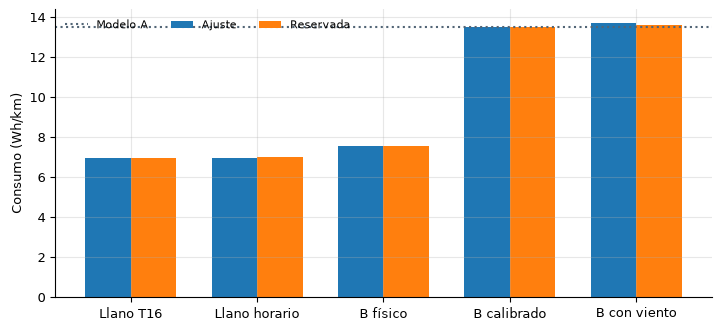

In [2]:
series = {
    "Llano T16": "llano_t16_wh_km", "Llano horario": "llano_horario_wh_km",
    "B físico": "b_bruto_wh_km", "B calibrado": "b_wh_km",
    "B con viento": "viento_wh_km",
}
intensidades = fisico[["periodo", *series.values(), "rango_bajo_wh_km", "rango_alto_wh_km"]]
guardar(intensidades, "T41_intensidades.csv")
fig, ax = plt.subplots(figsize=(7.1, 3.2), layout="constrained")
x = np.arange(len(series))
for j, (periodo, fila) in enumerate(f.iterrows()):
    ax.bar(x + .36*(j-.5), [fila[c] for c in series.values()], width=.36, label=periodo.capitalize())
ax.axhline(ref, color="#526576", ls=":", label="Modelo A")
ax.set(xticks=x, xticklabels=list(series), ylabel="Consumo (Wh/km)")
ax.legend(frameon=False, ncol=3)
guardar_figura(fig, "consumo", "T41_intensidades")

## T42 · Desnivel de extremos

Se archivan coordenadas deduplicadas y elevaciones del píxel más próximo de Copernicus GLO-30 Public. Es un modelo de superficie con referencia vertical EGM2008, paso de un segundo de arco y error vertical absoluto publicado inferior a 4 m LE90. La estimación usa origen y destino. Puede incorporar tejados, puentes o error GPS. No observa subidas y bajadas intermedias. La diferencia B con y sin desnivel utiliza los mismos viajes, meteorología y demás parámetros. [Ficha GLO-30](https://dataspace.copernicus.eu/explore-data/data-collections/copernicus-contributing-missions/collections-description/COP-DEM)

,periodo,viajes,suben,bajan,mediana_m,p05_m,p95_m,p95_abs_m,aporte_kwh,aporte_medio_wh
0,ajuste,16756,8836,7735,0.886,-26.643,30.268,36.713,9.552,0.570
1,reservada,6614,3555,2979,1.004,-26.267,31.217,37.892,4.120,0.623


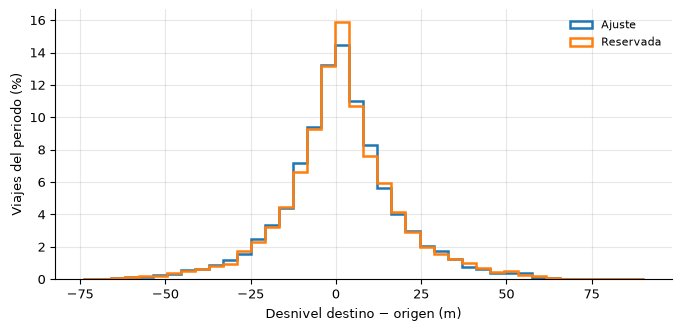

In [3]:
display(desnivel.round(3))
fig, ax = plt.subplots(figsize=(6.7, 3.2), layout="constrained")
bordes = np.histogram_bin_edges(v["desnivel_m"], bins=40)
for p, g in v.groupby("periodo"):
    ax.hist(g["desnivel_m"], bins=bordes, weights=np.full(len(g), 100/len(g)), histtype="step", linewidth=1.8, label=p.capitalize())
ax.set(xlabel="Desnivel destino − origen (m)", ylabel="Viajes del periodo (%)")
ax.legend(frameon=False)
guardar_figura(fig, "consumo", "T42_desnivel")

## T43 · Escala y discrepancias por viaje

La escala \(k\) multiplica rodadura y aire y se resuelve una sola vez en el ajuste para que \(\sum E_B / \sum d_{km} = 13{,}5\) Wh/km. Resume arranques, frenadas, rodeos y pérdidas omitidas; el desnivel conserva su trabajo físico y la electrónica su potencia. No estima una eficiencia real. Como contraste se guarda la calibración anterior, que escalaba toda la energía, incluido el desnivel, y dejaba en cero los viajes que bajan. La reservada reutiliza la misma escala. Se miden la diferencia absoluta de Wh, los mayores casos y el contraste por velocidad y signo del desnivel. Las fronteras de velocidad son cuartiles del ajuste.

,periodo,velocidad,pendiente,viajes,diferencia_media_wh
0,ajuste,"(-inf, 2.576]",baja,1938,-7.02
1,ajuste,"(-inf, 2.576]",igual,132,-3.53
2,ajuste,"(-inf, 2.576]",sube,2119,-0.25
3,ajuste,"(2.576, 3.461]",baja,1881,-6.27
4,ajuste,"(2.576, 3.461]",igual,35,-3.74
5,ajuste,"(2.576, 3.461]",sube,2273,1.56
6,ajuste,"(3.461, 4.254]",baja,1899,-4.34
7,ajuste,"(3.461, 4.254]",igual,15,-0.28
8,ajuste,"(3.461, 4.254]",sube,2275,4.80
9,ajuste,"(4.254, inf]",baja,2017,-0.65


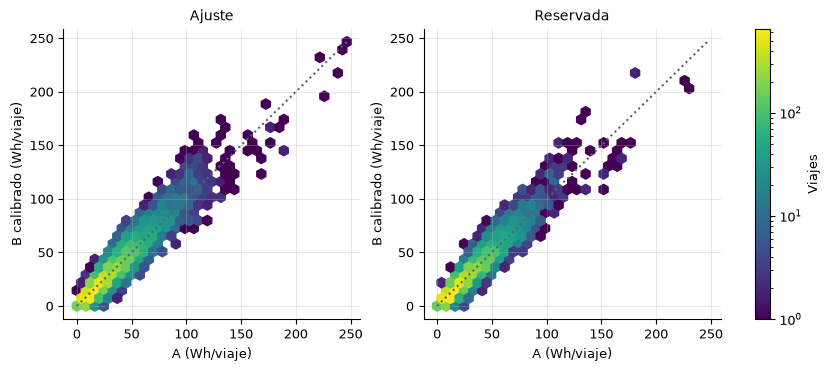

In [4]:
q = v.loc[v["periodo"].eq("ajuste"), "velocidad_m_s"].quantile([.25, .5, .75]).tolist()
grupos = v.assign(velocidad=pd.cut(v["velocidad_m_s"], [-np.inf, *q, np.inf]).astype(str),
                  pendiente=np.where(v["desnivel_m"] > 0, "sube", np.where(v["desnivel_m"] < 0, "baja", "igual")))
cortes = grupos.groupby(["periodo", "velocidad", "pendiente"], as_index=False)["delta_b_a_wh"].agg(
    viajes="size", diferencia_media_wh="mean")
display(guardar(cortes, "T43_velocidad_desnivel.csv").round(2))
fig, ejes = plt.subplots(1, 2, figsize=(8.2, 3.6), layout="constrained")
for ax, (periodo, g) in zip(ejes, v.groupby("periodo")):
    limite = max(v["energia_wh_a"].max(), v["energia_wh_b"].max())
    imagen = ax.hexbin(g["energia_wh_a"], g["energia_wh_b"], gridsize=30, mincnt=1,
                       bins="log", cmap="viridis", extent=(0, limite, 0, limite))
    ax.plot([0, limite], [0, limite], ":", color="#526576")
    ax.set(title=periodo.capitalize(), xlabel="A (Wh/viaje)", ylabel="B calibrado (Wh/viaje)")
fig.colorbar(imagen, ax=ejes, label="Viajes")
guardar_figura(fig, "consumo", "T43_viajes")

In [5]:
dn = desnivel.set_index("periodo")
display(Markdown(f"""## Conclusiones
- El llano de T16 da **{a.llano_t16_wh_km:.2f} Wh/km** en ajuste. Con densidad horaria y desnivel, el B físico da **{a.b_bruto_wh_km:.2f} Wh/km**.
- El desnivel cambia el total del ajuste en **{dn.loc['ajuste', 'aporte_kwh']:.2f} kWh** antes de escalar. El 95 % de los viajes tiene un desnivel absoluto de hasta **{dn.loc['ajuste', 'p95_abs_m']:.1f} m**.
- Con **k = {a.k:.4f}** sobre rodadura y aire, B da **{a.b_wh_km:.2f} Wh/km** en ajuste y **{r.b_wh_km:.2f} Wh/km** fuera del ajuste. El error absoluto medio entre modelos es **{r.mae_wh:.2f} Wh/viaje** en reserva.
- Ningún viaje queda en 0 Wh: **{int(a.traccion_nula_b)}** viajes del ajuste bajan sin tracción y solo gastan la electrónica. Con la calibración anterior quedaban **{int(a.cero_calibracion_total)}** viajes en cero.
- Con el viento a la altura del conductor, B da **{a.viento_wh_km:.2f} Wh/km** en ajuste."""))

## Conclusiones
- El llano de T16 da **6.96 Wh/km** en ajuste. Con densidad horaria y desnivel, el B físico da **7.55 Wh/km**.
- El desnivel cambia el total del ajuste en **9.55 kWh** antes de escalar. El 95 % de los viajes tiene un desnivel absoluto de hasta **36.7 m**.
- Con **k = 1.8587** sobre rodadura y aire, B da **13.50 Wh/km** en ajuste y **13.53 Wh/km** fuera del ajuste. El error absoluto medio entre modelos es **5.34 Wh/viaje** en reserva.
- Ningún viaje queda en 0 Wh: **244** viajes del ajuste bajan sin tracción y solo gastan la electrónica. Con la calibración anterior quedaban **814** viajes en cero.
- Con el viento a la altura del conductor, B da **13.71 Wh/km** en ajuste.